# Integrated Pipeline: AI Parts 1 to 3 and MI Parts 1 to 3 as one system
Provider Network Access and Cost Planner · David Satizabal · CAI4505C and CAI4510C

Each Part folder still runs on its own. This notebook imports their code in place (no copies) and passes work between them like a relay team:

| Stage | Who | What it hands on |
|---|---|---|
| 0 | Sync check | Proof that every Part's copy of the shared data and code is identical |
| 1 | MI 1, MI 2, MI 3 | Each member's predicted dollars, high-cost flag, "model is unsure" flag, HMM watch list |
| 2 | AI 1 (+ MI 1, MI 2) | Seats members with doctors, puts dollars on every panel, reports the seats left |
| 3 | AI 3 (+ AI 1, MI 3) | Reads a chat request and matches it to a doctor who still has a seat |
| 4 | AI 2 (+ MI 3, AI 3) | Sorts scanned documents; referrals become requests in Stage 3 |

All data is synthetic and seeded (seed 42).

In [1]:
# Find the repo. If it's missing: clone the class repo, and if that fails, ask for the repo zip
import sys, os, zipfile, subprocess
from pathlib import Path

FOLDER = "Integrated_Pipeline"
CANDIDATES = [Path.cwd(), Path.cwd() / FOLDER, Path("/content/Artificial-Intelligence-Class") / FOLDER,
              Path("/content/Artificial-Intelligence-Class-finalProject") / FOLDER]
find = lambda: next((p for p in CANDIDATES if (p / "src" / "run_pipeline.py").exists()), None)
PROJECT = find()

if PROJECT is None and Path("/content").exists():
    subprocess.run(["git", "clone", "-q", "-b", "finalProject", "https://github.com/DASatizabal/Artificial-Intelligence-Class",
                    "/content/Artificial-Intelligence-Class"])
    PROJECT = find()

if PROJECT is None:
    try:
        from google.colab import files
        print("Repo not found. Upload the whole repo as a zip (this folder needs every Part folder next to it)")
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
        PROJECT = find()
    except ImportError:
        raise FileNotFoundError("Open this notebook from the Integrated_Pipeline folder of the repo, or run it in Colab.")

os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))
print("Project folder:", PROJECT.name)

Project folder: Integrated_Pipeline


This cell finds the repo. Unlike the Part notebooks, this one needs every Part folder, so the fallback upload is the whole repo zip.

In [2]:
import sync_check
rows = sync_check.check()

OK    5 copies  data/kb/county_grid.csv
OK    5 copies  data/kb/zip_cells.csv
OK    5 copies  data/kb/providers.csv
OK    5 copies  data/kb/access_standards.csv
OK    4 copies  data/kb/provider_slots.csv
OK    3 copies  data/members_part1.csv
OK    3 copies  data/member_months.csv
OK    2 copies  data/labels.csv
OK    5 copies  src/kb.py
OK    3 copies  src/gen_claims.py
OK    2 copies  src/gen_docs.py
OK    2 copies  src/dataset.py
OK    2 copies  data/images/*.png
OK    2 copies  MI_Part2_Classification/outputs/predicted_high_cost_flags.csv -> AI_Part1_Search_CSP/data/predicted_high_cost_flags.csv
OK    2 copies  AI_Part1_Search_CSP/data/members.csv -> MI_Part1_EDA_Regression/data/members_part1.csv


**Stage 0, sync check.** Each Part carries its own copy of the county map, the doctors, the claims and the images so it can run alone in Colab. Copies can drift apart, like two people editing their own printout of the same spreadsheet. This check hashes every copy and stops with an error if any one differs. Every line should say OK.

In [3]:
import json, pandas as pd
import run_pipeline
run_pipeline.main()

Stage 0: sync check
Stage 1: member scoring


Stage 2: planner + cost


Stage 3: front door


Stage 4: documents


{
 "seed": 42,
 "sync_check": {
  "files_checked": 15,
  "all_identical": true
 },
 "reproduced_from_parts": {
  "mi1_linear_test_mae": 2167.622,
  "mi3_mlp_test_roc_auc": 0.7553,
  "ai1_placed": 465,
  "ai1_avg_miles": 4.85,
  "ai3_intent_test_accuracy": 0.9945,
  "softmax_messy_accuracy": 0.9967,
  "cnn_messy_accuracy": 0.97
 },
 "member_scoring": {
  "month": "2026-02",
  "members": 600,
  "mi1_linear_test_mae_check": 2167.622,
  "mlp_test_roc_auc": 0.7553,
  "hmm_flag_line": 0.1472,
  "negative_cost_predictions_clipped": 25,
  "high_cost_flagged": 60,
  "needs_review": 60,
  "review_sd_line": 0.0375,
  "needs_review_and_flagged": 7,
  "watch_list": 22,
  "predicted_cost_total": 1121885.34,
  "flagged_share_of_predicted_cost": 0.2629
 },
 "front_door_chat": {
  "answers": 218,
  "actions": {
   "escalate": 42,
   "accept": 81,
   "reject": 48,
   "ask_clarify": 16,
   "inform": 24,
   "block": 7
  },
  "integration_rules_fired": {
   "I1": 11,
   "I2": 23,
   "I3": 22,
   "I4": 36,


This runs all four stages (under a minute on a CPU). Before using any model, each stage retrains it with its Part's own code and seed and **checks that it reproduces the number that Part reported** (for example MI 1's MAE of $2,167.62 and AI 1's 465 placed members). If a number didn't match, the run would stop. So the pipeline is provably using the same models the Part reports describe.

In [4]:
m = json.load(open("outputs/metrics.json"))
s = pd.read_csv("outputs/member_scores.csv")
print(json.dumps(m["member_scoring"], indent=1))
s.sort_values("p_high_cost", ascending=False).head(8)

{
 "month": "2026-02",
 "members": 600,
 "mi1_linear_test_mae_check": 2167.622,
 "mlp_test_roc_auc": 0.7553,
 "hmm_flag_line": 0.1472,
 "negative_cost_predictions_clipped": 25,
 "high_cost_flagged": 60,
 "needs_review": 60,
 "review_sd_line": 0.0375,
 "needs_review_and_flagged": 7,
 "watch_list": 22,
 "predicted_cost_total": 1121885.34,
 "flagged_share_of_predicted_cost": 0.2629
}


,member_id,pred_cost_next_3m_raw,pred_cost_next_3m,p_high_cost,high_cost_flag,p_high_mlp_mc,sd_mlp_mc,p_spell_3m_hmm,needs_review,watch_list
230,M0231,11360.35,11360.35,0.9875,1,0.9748,0.0156,0.3456,0,0
218,M0219,7384.40,7384.40,0.9426,1,0.8477,0.0278,0.1535,0,0
62,M0063,7746.54,7746.54,0.9409,1,0.8461,0.0389,0.1654,1,0
265,M0266,6857.41,6857.41,0.9397,1,0.8955,0.0236,0.2670,0,0
56,M0057,7030.89,7030.89,0.9390,1,0.8746,0.0260,0.2816,0,0
310,M0311,8941.02,8941.02,0.9281,1,0.8725,0.0442,0.3456,1,0
321,M0322,6372.32,6372.32,0.9268,1,0.8701,0.0304,0.1774,0,0
313,M0314,6804.58,6804.58,0.9166,1,0.8921,0.0211,0.3176,0,0


**Stage 1, member scoring.** Every planner member gets a report card from all three MI Parts:
- **MI 1** predicted next-quarter dollars. The linear model is used because the planner adds dollars up per doctor; MI 1's log model predicts the typical (median) member, which undercounts totals. 25 negative predictions were set to $0, since a bill can't be negative.
- **MI 2** chance of being high-cost, and the top-10% flag (60 members) that the planner uses.
- **MI 3** MC Dropout spread: the 60 members the MLP is least sure about get a "care team review" note. Only 7 of them are also flagged, so this catches different people.
- **MI 3** HMM: 22 members the HMM thinks are heading into a high-cost spell, but whom MI 2 did not flag, go on a watch list.

The 60 flagged members carry 26.3% of the predicted dollars.

{'placed': 465, 'avg_miles': 4.85, 'predicted_cost_placed_members': 815026.57, 'predicted_cost_unplaced_members': 306858.77, 'seats_left_total': 229}
         placed  avg_miles  panels  max_high_cost_in_one_panel  highest_cost_per_member  lowest_cost_per_member  cost_per_member_cv  worst_panel_vs_specialty_average
cap on      465       4.85      67                           2                  4970.85                     0.0              0.4126                             2.175
cap off     465       4.85      67                           2                  4970.85                     0.0              0.4105                             2.175
 flagged_share  flagged  placed_cap  max_high_cost_in_one_panel_cap  panels_over_real_cap_cap  placed_no_cap  max_high_cost_in_one_panel_no_cap  panels_over_real_cap_no_cap
           0.1       60         465                               2                         0            465                                  2                            0
      

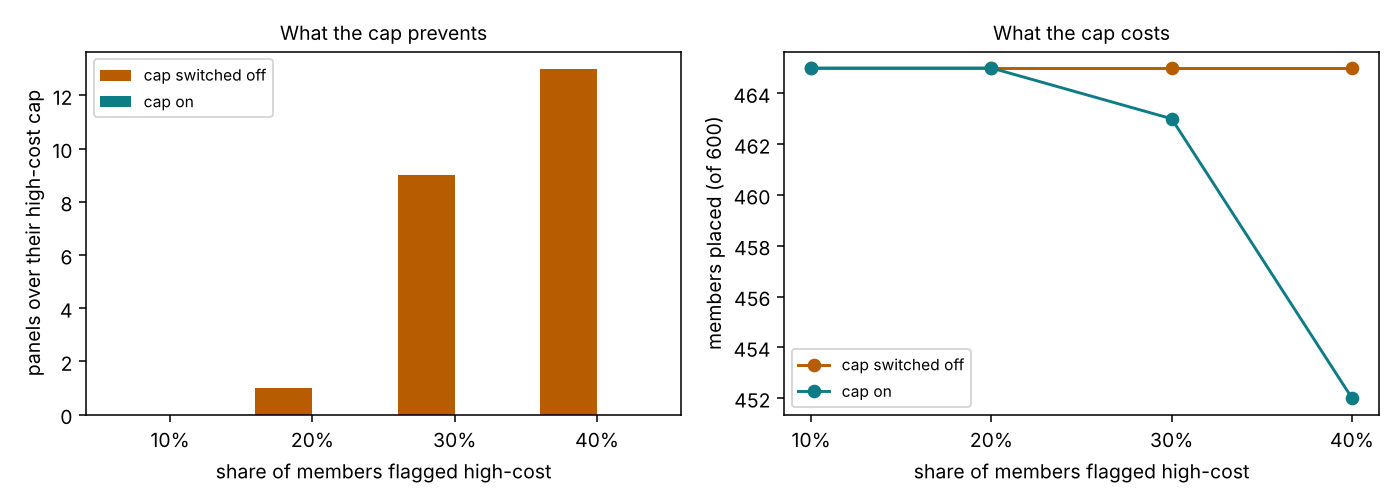

In [5]:
from IPython.display import Image, display
pc = m["planner_cost"]
print({k: pc[k] for k in ("placed", "avg_miles", "predicted_cost_placed_members", "predicted_cost_unplaced_members", "seats_left_total")})
print(pd.DataFrame([pc["with_high_cost_cap"], pc["without_high_cost_cap"]], index=["cap on", "cap off"]).to_string())
print(pd.DataFrame(pc["cap_sensitivity"]).to_string(index=False))
display(Image("outputs/cap_sensitivity.png"))

**Stage 2, planner and cost.** AI 1's planner seats the members using MI 2's flag (same result as AI 1: 465 placed, 4.85 miles), and every panel now has a dollar total (`outputs/panel_costs.csv`). The 135 members who could not be seated carry $306,859 of predicted cost, which is the money tied to the access gaps.

**Honest finding about the high-cost cap.** At 10% flagged, switching the cap off changes nothing: no panel ever has more than 2 flagged members. The sensitivity test flags more members to see when the cap starts to matter. At 30% flagged, 9 panels would go over their cap without it. At 40%, 13 would go over; with the cap on, no panel goes over, but 13 fewer members get seated. So the cap is insurance for a sicker population. It doesn't do any work for this one.

In [6]:
a = json.load(open("outputs/answers.json"))
print(json.dumps(m["front_door_chat"], indent=1))
for rid in ("R0166", "R0267", "C001"):
    x = next(r for r in a if r["request_id"] == rid)
    print(f"\n{rid}: {x['text']}\n  action: {x['action']}  |  {x['message']}")
    print("  rules:", [t["rule"] for t in x["proof_trace"]])

{
 "answers": 218,
 "actions": {
  "escalate": 42,
  "accept": 81,
  "reject": 48,
  "ask_clarify": 16,
  "inform": 24,
  "block": 7
 },
 "integration_rules_fired": {
  "I1": 11,
  "I2": 23,
  "I3": 22,
  "I4": 36,
  "I5": 10,
  "I6": 16,
  "I7": 11
 },
 "searches_matched_against_seats": 92,
 "ai3_top_pick_was_full": 66,
 "new_seats_taken": 51,
 "high_cost_members": 29,
 "with_review_or_watch_note": 25
}

R0166: Every gynecologist near 33012 is full
  action: inform  |  Complaint logged. Dr. Chavez is full. Dr. Hill is 12 miles away and can take you.
  rules: ['Rt1', 'Rs2', 'Rt3', 'R15', 'I3', 'I7']

R0267: Switch my primary care doctor to Dr. Rios
  action: reject  |  That doctor's open seats were all used by this month's plan.
  rules: ['Rn2', 'Rt1', 'R16', 'Rt3', 'I5']

C001: My mom needs a heart specialist somewhere around 33155 who talks Spanish
  action: escalate  |  Every matching doctor inside the distance limit is full. Logged for the network team.
  rules: ['Rt1', 'Rs1', 'Rt3

**Stage 3, front door.** AI 3 reads each of its 218 held-out and challenge requests exactly as before (intent, slots, rules). Then integration rules I1 to I7 check the answer against the seats the planner left. They are added to the same proof trace, so every answer still explains itself.

The big number: in **66 of the 92** searches, AI 3's top pick had **no seat left** after the plan. On its own, AI 3 would have sent those members to a full doctor. Now I3 moves 22 of them to a farther doctor who is still inside the limit and has a seat, and I4 escalates 36 as capacity gaps for the network team. I5 caught 10 PCP changes to doctors whose seats the plan had already used. I6 and I7 add the MI 3 review and watch-list notes.

The requests carry no member ID, so each one is paired at random (seed 42) with a planner member from the same ZIP. That lets the risk scores ride along; the pairing itself is synthetic.

In [7]:
d = m["documents"]
print(pd.DataFrame({k: {kk: vv for kk, vv in v.items() if not isinstance(vv, dict)} for k, v in d.items()}).T.to_string())
print("strict both-agree rule:", {k: v["strict_both_agree_rule"] for k, v in d.items()})
print("CNN alone:", {k: v["cnn_alone"] for k, v in d.items()})
print(json.dumps(m["front_door_referrals"], indent=1))
print(pd.DataFrame(m["open_seats_by_specialty"]).T)

       documents  auto_routed  auto_share  wrong_auto_routes  sent_to_human  human_queue_that_softmax_had_wrong  readers_disagree
test       180.0        180.0      1.0000                0.0            0.0                                 0.0               0.0
messy      300.0        298.0      0.9933                0.0            2.0                                 1.0              10.0
strict both-agree rule: {'test': {'auto_routed': 180, 'wrong_auto_routes': 0}, 'messy': {'auto_routed': 288, 'wrong_auto_routes': 0}}
CNN alone: {'test': {'auto_routed': 180, 'wrong_auto_routes': 0}, 'messy': {'auto_routed': 297, 'wrong_auto_routes': 7}}
{
 "answers": 160,
 "actions": {
  "accept": 21,
  "escalate": 120,
  "reject": 19
 },
 "integration_rules_fired": {
  "I2": 11,
  "I3": 10,
  "I4": 120,
  "I6": 9,
  "I7": 12
 },
 "searches_matched_against_seats": 141,
 "ai3_top_pick_was_full": 130,
 "new_seats_taken": 21,
 "high_cost_members": 21,
 "with_review_or_watch_note": 20
}
                   

**Stage 4, documents.** AI 2's softmax (the better reader on messy scans, 0.997 vs the CNN's 0.970) routes any scan it is at least 70% sure of. MI 3's CNN reads every scan too, as a second opinion, and adds a note when it disagrees.

I also tested a stricter rule: auto-route only when both readers agree. On the 300 messy scans it sent 10 more scans to a person and caught **zero** extra mistakes, because the softmax's only mistake was already under the 70% line. The CNN alone would have made 7 wrong auto-routes. So the stricter rule was measured but not used. Same lesson as MI all term: the simpler, better-validated model wins.

Each auto-routed referral (160) becomes a find-provider request in Stage 3. **120 of them escalate**: after the plan and the chat requests, only 87 specialist seats were left, and endocrinology and OB-GYN ran out completely. That's the kind of finding a network team acts on: the open specialist seats can't absorb a month of referrals.

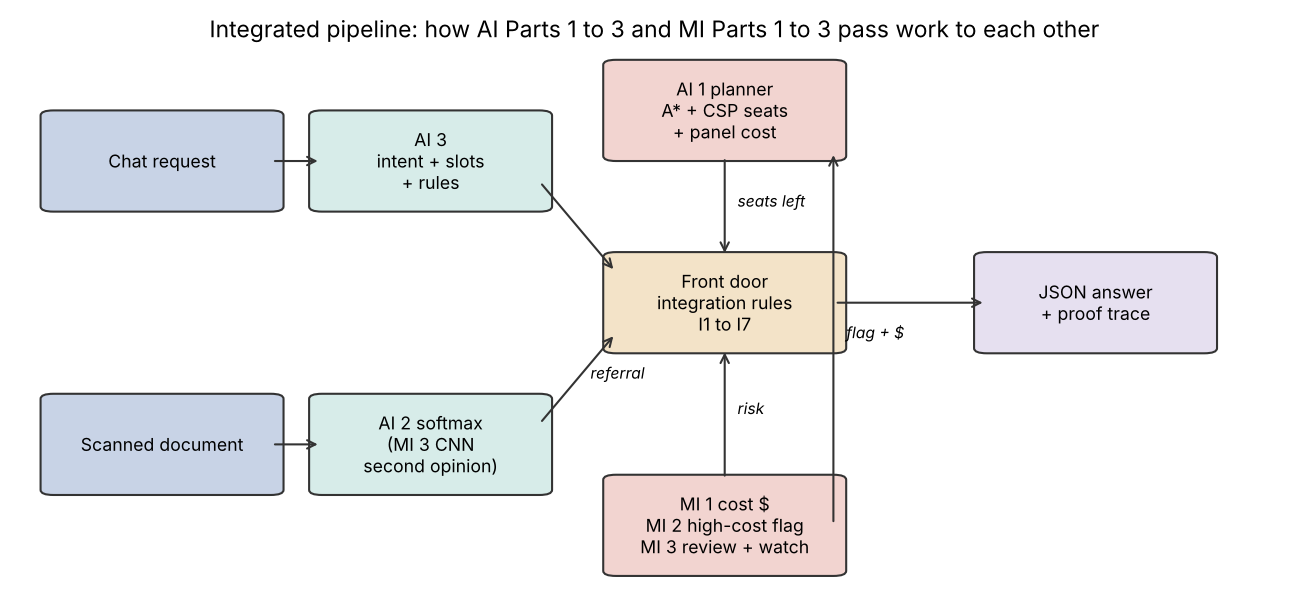

['request_id',
 'source',
 'text',
 'member',
 'intent',
 'confidence',
 'slots',
 'action',
 'message',
 'matched_provider',
 'ai3_top_pick',
 'notes',
 'proof_trace']

In [8]:
display(Image("outputs/pipeline_diagram.png"))
json.load(open("outputs/answer_schema.json"))["required"]

**The contract.** Every one of the 378 answers (218 chat, 160 referral) is one JSON object, and each is checked against `outputs/answer_schema.json` with `jsonschema` before it is saved. A broken answer would stop the run.

## Summary
| Link | Before | Now |
|---|---|---|
| MI 2 → AI 1 | placeholder flag | planner seats members by MI 2's prediction |
| MI 1 → AI 1 | dollars unused | every panel has a predicted dollar total; unplaced members carry $306,859 |
| AI 1 → AI 3 | AI 3 picked the nearest doctor, full or not | 66 of 92 top picks were full; rerouted or escalated |
| MI 3 → AI 3 | uncertainty and HMM unused | review notes (I6) and watch-list notes (I7) on answers |
| AI 2 / MI 3 → AI 3 | document label unused | referrals become requests; CNN is a second opinion |
| All Parts | copies could drift | sync check over 15 shared files |